# 数据结构与科学计算 · 第 05 讲
## 树、堆、优先队列与自适应网格（AMR）

> **课程定位**：面向已经学习 Python 基础、正在准备自行编写二维 CFD 求解器的学习者。本讲从数据结构原理出发，以实际数值计算问题作为应用练习。

**完成本讲后，你应该能够：**

1. 区分树的根、父节点、子节点、叶子与树高；
2. 掌握二叉树前序 / 中序 / 后序遍历以及递归栈开销；
3. 理解堆（Heap）与二叉搜索树（BST）不是同一个结构；
4. 用 `heapq` 管理带优先级的数值计算任务；
5. 理解四叉树（Quadtree）如何描述二维自适应网格层级。

**预计学习时间**：90–130 分钟。所有核心示例可在 VS Code 的 Jupyter Notebook 中直接运行。

## 0. 使用方法与运行环境

1. 在 VS Code 打开此 `.ipynb`，右上角选择当前项目的 Python Kernel；
2. 使用 `Shift + Enter` 依次运行。修改代码后，建议 **Restart Kernel & Run All** 以消除旧变量干扰；
3. **练习单元以 `TODO` 留空**，后面会有逐项自动检查；未完成练习时显示“尚未通过”是预期行为；
4. 最后附有独立命名的 `_solution` 参考实现，不会覆盖你的练习函数；
5. 学习重点是“选择什么结构、为什么、代价是什么”，不只是背诵 API。

前两讲已安装 NumPy。本系列推荐运行 `uv pip install numpy scipy matplotlib ipykernel jupyter`。第 08 讲还需要 JAX：`uv pip install -U jax`（此命令默认安装适用于当前平台的发行版，GPU 支持视平台而定）。

In [1]:
import sys
print('Python:', sys.version.split()[0])
print('Notebook 已连接到 Python Kernel')

Python: 3.13.5
Notebook 已连接到 Python Kernel


## 1. 什么是树？

树是描述**层级关系**的图结构：除根以外，每个节点恰好有一个父节点。

- **根 root**：没有父节点；
- **叶 leaf**：没有子节点；
- **深度 depth**：从根到节点的边数，根深度为 0；
- **高度 height**：从节点往下到最远叶子的最长路径长度（此课练习采用“节点层数”作为树高：空树 0、单节点树 1）；
- **子树**：任意节点及其全部后代。

二叉树每个节点最多有两个子节点。它不自动满足“左小右大”；只有**二叉搜索树**具备对应的排序约束。

对于节点数 $n$、高度 $h$：一次 DFS 遍历 $O(n)$；递归调用栈额外占用 $O(h)$。

In [2]:
from dataclasses import dataclass
from typing import Optional

@dataclass
class TreeNode:
    value: int
    left: Optional['TreeNode'] = None
    right: Optional['TreeNode'] = None

#        8
#       / \
#      3   10
#     / \
#    1   6
root = TreeNode(8,
    TreeNode(3, TreeNode(1), TreeNode(6)),
    TreeNode(10))
print(root)

TreeNode(value=8, left=TreeNode(value=3, left=TreeNode(value=1, left=None, right=None), right=TreeNode(value=6, left=None, right=None)), right=TreeNode(value=10, left=None, right=None))


## 2. 前序、中序、后序遍历

遍历表示**什么时候处理当前节点**：

- 前序：根 → 左 → 右
- 中序：左 → 根 → 右
- 后序：左 → 右 → 根

对于二叉搜索树（BST），中序遍历通常得到升序序列（若允许重复值，规则需要事先约定）。

In [3]:
def preorder(node):
    if node is None:
        return []
    return [node.value] + preorder(node.left) + preorder(node.right)

def inorder(node):
    if node is None:
        return []
    return inorder(node.left) + [node.value] + inorder(node.right)

def postorder(node):
    if node is None:
        return []
    return postorder(node.left) + postorder(node.right) + [node.value]

print('pre: ',preorder(root))
print('in:  ',inorder(root))
print('post:',postorder(root))

pre:  [8, 3, 1, 6, 10]
in:   [1, 3, 6, 8, 10]
post: [1, 6, 3, 10, 8]


### 2.1 为什么“平衡”很重要？

普通二叉搜索树的查找成本为 $O(h)$。如果数据插入顺序接近排序，普通 BST 可能退化为链表，树高达到 $O(n)$；平衡搜索树则可以将高度控制在 $O(\log n)$。

此处仅演示普通 BST，不实现 AVL / 红黑树旋转；Python 的内置 `dict` 底层是哈希表，并不是 BST。

In [4]:
def bst_insert(node, value):
    if node is None:
        return TreeNode(value)
    if value < node.value:
        node.left = bst_insert(node.left, value)
    elif value > node.value:
        node.right = bst_insert(node.right, value)
    return node

balanced_like = None
for v in [4,2,6,1,3,5,7]:
    balanced_like = bst_insert(balanced_like,v)

skewed = None
for v in [1,2,3,4,5,6,7]:
    skewed = bst_insert(skewed,v)

print('BST sorted traversal:', inorder(balanced_like))
print('skewed sorted traversal:',inorder(skewed))

BST sorted traversal: [1, 2, 3, 4, 5, 6, 7]
skewed sorted traversal: [1, 2, 3, 4, 5, 6, 7]


## 3. 堆（Heap）不是二叉搜索树

**最小堆**保证每个父节点的优先级不大于其子节点，但**不会对每一条左/右子树整体排序**。它最擅长的操作是反复提取“最优先”的一个元素。

Python `heapq` 在 `list` 上实现二叉最小堆：

| 操作 | 时间复杂度 |
|:--|:--:|
| 读取堆顶 `h[0]` | $O(1)$ |
| `heappush` | $O(\log n)$ |
| `heappop` | $O(\log n)$ |
| `heapify` 列表 | $O(n)$ |

heapq 不为所有普通元素提供直接的 $O(1)$ 删除操作，且堆内数组并非排序数组。

In [5]:
import heapq
h = [9, 1, 5, 3, 7]
heapq.heapify(h)
print('internal heap array:', h)
heapq.heappush(h,2)
print('pop sequence:',[heapq.heappop(h) for _ in range(len(h))])

internal heap array: [1, 3, 5, 9, 7]
pop sequence: [1, 2, 3, 5, 7, 9]


### 3.1 优先队列：把“任务顺序”交给优先级

计算任务经常需要按照估计误差（AMR）、剩余耗时或事件发生时间优先处理。当任务本身不可比较、优先级可能相同，可添加单调递增的序号，以避免 Python 尝试比较任务对象。

In [6]:
from itertools import count

counter = count()
tasks = []
for priority, task in [(2.0, {'job':'B'}), (1.0, {'job':'A'}), (1.0, {'job':'C'})]:
    heapq.heappush(tasks, (priority, next(counter), task))

while tasks:
    priority, _, task = heapq.heappop(tasks)
    print('run:', task['job'], 'priority:', priority)

run: A priority: 1.0
run: C priority: 1.0
run: B priority: 2.0


## 4. 二维四叉树与 AMR

将二维矩形网格单元递归划分为四个子矩形，就得到四叉树。一个节点代表一个**空间区域**，不是单独的数值节点。对非均匀场，我们可以在变化剧烈的区域细分、在平滑区域保留粗网格。

$$\text{refine if } \eta(\Omega) > \varepsilon \quad\text{and}\quad \ell < \ell_{\max}.$$

这里 $\eta$ 是误差或特征指标，$\varepsilon$ 是细分阈值，$\ell$ 是当前细分层数。课程演示使用采样值差异作为**教学用代理指标**，并不是可靠的 CFD 误差估计器。

实际 AMR 还涉及守恒量转移、细/粗网格通量匹配、悬挂节点和 2:1 平衡约束等。

In [7]:
from dataclasses import dataclass, field
import math

@dataclass
class QuadCell:
    x0: float
    x1: float
    y0: float
    y1: float
    level: int = 0
    children: list = field(default_factory=list)

    def split(self):
        xm, ym = (self.x0+self.x1)/2, (self.y0+self.y1)/2
        self.children = [
            QuadCell(self.x0, xm, self.y0, ym, self.level+1),
            QuadCell(xm, self.x1, self.y0, ym, self.level+1),
            QuadCell(self.x0, xm, ym, self.y1, self.level+1),
            QuadCell(xm, self.x1, ym, self.y1, self.level+1),
        ]

def leaves(node):
    if not node.children:
        return [node]
    return [leaf for child in node.children for leaf in leaves(child)]

mesh_tree = QuadCell(0, 1, 0, 1)
mesh_tree.split()
mesh_tree.children[0].split()
print('number of leaf cells:',len(leaves(mesh_tree)))
print('levels:',[c.level for c in leaves(mesh_tree)])

number of leaf cells: 7
levels: [2, 2, 2, 2, 1, 1, 1]


### 4.1 一次完整的自适应细分与可视化

选用一个具有局部尖峰的二维标量场，细化中心附近的单元。为了观察空间分辨率的变化，使用 Matplotlib 画出每个叶子单元边框。

In [8]:
import numpy as np

def scalar_field(x, y):
    return math.exp(-60 * ((x-0.68)**2+(y-0.42)**2))

def indicator(c):
    pts = [(c.x0,c.y0),(c.x1,c.y0),(c.x0,c.y1),(c.x1,c.y1),
           ((c.x0+c.x1)/2,(c.y0+c.y1)/2)]
    vals = [scalar_field(x,y) for x,y in pts]
    return max(vals)-min(vals)

def refine_by_indicator(c, threshold=0.12, max_level=5):
    if c.level >= max_level:
        return
    if indicator(c) > threshold:
        c.split()
        for child in c.children:
            refine_by_indicator(child, threshold, max_level)

adaptive = QuadCell(0,1,0,1)
# 顶层区域先划分一次，避免尖峰被过度平滑的采样忽略
adaptive.split()
for cell in adaptive.children:
    refine_by_indicator(cell)
print('adaptive leaf count:',len(leaves(adaptive)))

adaptive leaf count: 127


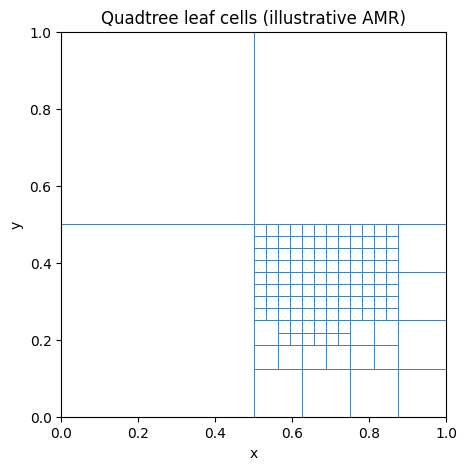

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(5, 5))
for c in leaves(adaptive):
    ax.add_patch(Rectangle((c.x0,c.y0),c.x1-c.x0,c.y1-c.y0,
                           fill=False,edgecolor='steelblue',linewidth=0.7))
ax.set(xlim=(0,1),ylim=(0,1),aspect='equal',xlabel='x',ylabel='y',
       title='Quadtree leaf cells (illustrative AMR)')
plt.show()

## 5. 工程上的权衡

- 堆适合“每次取最小误差/最大误差/最先到期任务”，不适合随机访问任意元素；
- 树适合层级空间剖分，但不等于所有 CFD 求解器都必须使用树；
- 实际大规模 CFD 的拓扑结构通常最终转化为紧凑索引数组或稀疏线性代数格式，在设备端进行批量计算；
- 树/堆的**算法结构**与数值场的**内存布局**是两件不同的事。

---
## 6. 编程练习

**练习 1**：实现 `tree_height(node)`，空树高度 0，单节点树高度 1。

In [10]:
def tree_height(node):
    # TODO: 递归计算左右子树的高度
    return None

**练习 2**：实现 `k_smallest(values,k)`，返回升序排列的最小 `k` 个值，允许重复元素；`0 <= k <= len(values)`，不要修改输入。请使用 `heapq`。

In [11]:
def k_smallest(values, k):
    # TODO: 可以构造堆再 heappop k 次
    return None

**练习 3**：实现 `count_leaves(node)`，统计四叉树叶节点数。未划分的根节点也是一个叶节点；需递归遍历所有子节点。

In [12]:
def count_leaves(node):
    # TODO: children 为空时返回 1
    return None

## 练习自测

运行下方测试。`TODO` 未完成时出现“尚未通过”属于正常情况；逐项填入你的实现并再次运行。本讲的测试检查正确性与边界条件，性能优化可在通过后继续尝试。

In [13]:
def check(name, test_fn):
    try:
        test_fn()
        print(f"✅ {name}：通过")
    except Exception as exc:
        print(f"⬜ {name}：尚未通过 — {type(exc).__name__}: {exc}")

In [14]:
def test_ex1():
    assert tree_height(None) == 0
    assert tree_height(TreeNode(1)) == 1
    assert tree_height(root) == 3
    assert tree_height(skewed) == 7

def test_ex2():
    xs = [5,2,2,9,1,7]; old = xs[:]
    assert k_smallest(xs,3) == [1,2,2]
    assert k_smallest(xs,0) == []
    assert k_smallest(xs,len(xs)) == sorted(xs)
    assert xs == old

def test_ex3():
    a = QuadCell(0,1,0,1)
    assert count_leaves(a) == 1
    a.split()
    assert count_leaves(a) == 4
    a.children[0].split()
    assert count_leaves(a) == 7

check('练习 1 / 树高',test_ex1)
check('练习 2 / 堆 Top-K',test_ex2)
check('练习 3 / 四叉树叶子计数',test_ex3)

⬜ 练习 1 / 树高：尚未通过 — AssertionError: 
⬜ 练习 2 / 堆 Top-K：尚未通过 — AssertionError: 
⬜ 练习 3 / 四叉树叶子计数：尚未通过 — AssertionError: 


## 7. 参考答案

In [15]:
def tree_height_solution(node):
    if node is None:
        return 0
    return 1 + max(tree_height_solution(node.left),tree_height_solution(node.right))

def k_smallest_solution(values,k):
    if not 0 <= k <= len(values):
        raise ValueError('k out of range')
    h = list(values)
    heapq.heapify(h)
    return [heapq.heappop(h) for _ in range(k)]

def count_leaves_solution(node):
    if not node.children:
        return 1
    return sum(count_leaves_solution(c) for c in node.children)

assert tree_height_solution(root) == 3
assert k_smallest_solution([3,1,2,1],2) == [1,1]
assert count_leaves_solution(mesh_tree) == 7
print('✅ 参考答案自测通过')

✅ 参考答案自测通过


## 8. 延伸：任务优先级与估计误差

设每个候选子区域的误差估计为 $\eta_i$。我们希望**优先处理误差最大的**单元。由于 `heapq` 是最小堆，存储 `(-eta, sequence, region)` 即可。

In [16]:
queue = []
for serial, (region, eta) in enumerate([('left',0.3),('center',0.9),('right',0.5)]):
    heapq.heappush(queue, (-eta,serial,region))
print('refinement order:',[heapq.heappop(queue)[2] for _ in range(len(queue))])

refinement order: ['center', 'right', 'left']


## 9. 思考与自测

1. BST 与二叉堆的结构约束有什么差别？
2. 为什么中序遍历只对满足 BST 排序规则的树保证非降序？
3. `heappush` 与 `heappop` 为什么是 $O(\log n)$？
4. 四叉树的一个节点代表网格节点，还是一个空间单元？
5. AMR 中为何需要额外考虑守恒量和粗细网格接口？

**选做**：用更可靠的梯度估计量替换教学的 `indicator`，观察细分阈值如何影响叶子数量和内存。下一讲正式学习一般图和非结构化网格。